### Dataset inventory: files per class folder and rejected extensions

In [1]:
from neurovision.data import scan_dataset, split_readable, find_duplicates, class_counts

scan = scan_dataset("../data/raw")
print("Files per folder:", scan["by_class"])
print("Rejected (bad extension):", scan["bad_ext"])

Files per folder: {'glioma': 1621, 'meningioma': 1645, 'notumor': 2000, 'pituitary': 1757}
Rejected (bad extension): []


### Readability check: count readable and corrupted images

In [2]:
ok, corrupted = split_readable(scan["valid"])
print(f"Readable: {len(ok)} | Corrupted: {len(corrupted)}")
print("Duplicates:", len(find_duplicates(ok)), "groups")

Readable: 7023 | Corrupted: 0
Duplicates: 194 groups


### Class distribution before cleaning

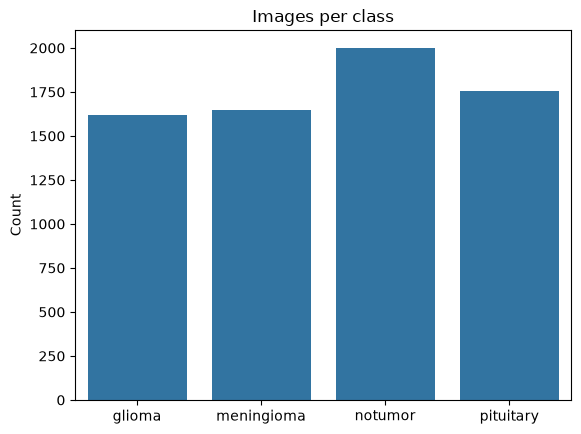

In [3]:
import seaborn as sns, matplotlib.pyplot as plt
counts = class_counts(ok)
sns.barplot(x=list(counts), y=list(counts.values()))
plt.title("Images per class"); plt.ylabel("Count")
plt.savefig("../reports/class_distribution.png", dpi=150); plt.show()

### Duplicate analysis: groups, redundant files, cross-class cases

In [4]:
dups = find_duplicates(ok)
extra = sum(len(g) - 1 for g in dups)
cross = [g for g in dups if len({label for _, label in g}) > 1]

print(f"{len(dups)} groups, {extra} redundant files")
print(f"Groups spanning different classes: {len(cross)}")

194 groups, 297 redundant files
Groups spanning different classes: 0


### Cleaning: build the deduplicated list (raw data untouched)

In [5]:
drop = {p for g in dups for p, _ in g[1:]}
drop |= {p for g in cross for p, _ in g}

ok_clean = [(p, l) for p, l in ok if p not in drop]
print(len(ok), "->", len(ok_clean), "images")
print(class_counts(ok_clean))

7023 -> 6726 images
Counter({'pituitary': 1740, 'notumor': 1731, 'meningioma': 1635, 'glioma': 1620})


### Class distribution after duplicate removal

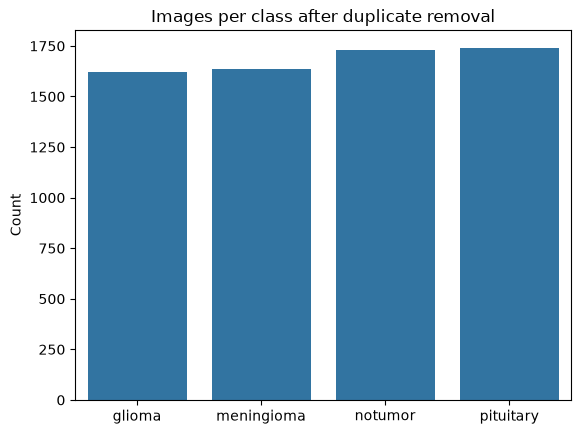

In [6]:
counts = class_counts(ok_clean)
sns.barplot(x=list(counts), y=list(counts.values()))
plt.title("Images per class after duplicate removal")
plt.ylabel("Count")
plt.savefig("../reports/class_distribution.png", dpi=150)
plt.show()

### Sample images per class

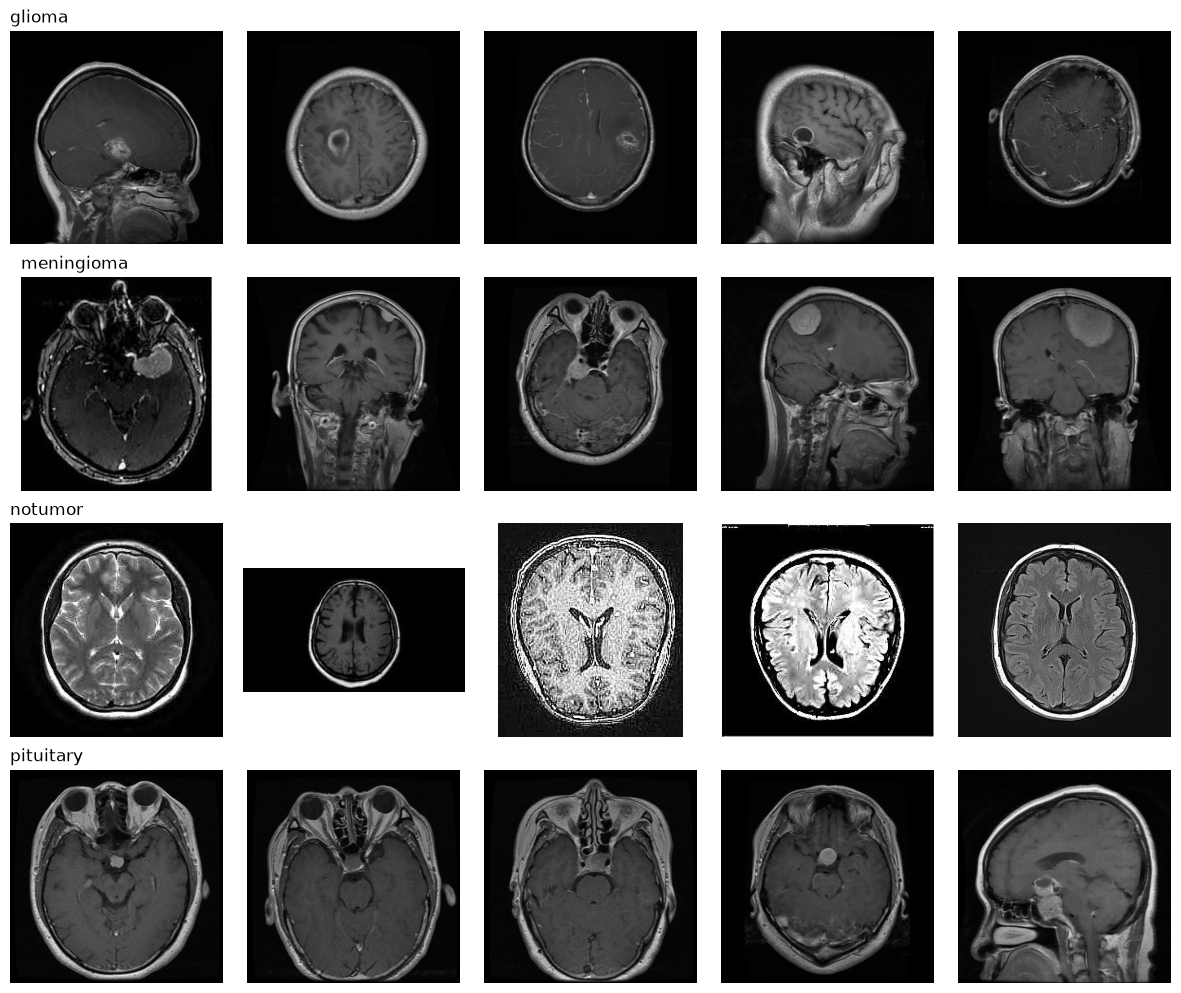

In [7]:
import random
import cv2
from neurovision.data import CLASSES

random.seed(42)
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 10))
for row, cls in enumerate(CLASSES):
    paths = [p for p, l in ok_clean if l == cls]
    for col, p in enumerate(random.sample(paths, 5)):
        img = cv2.imread(str(p))
        axes[row, col].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(cls, loc="left")
plt.tight_layout()
plt.savefig("../reports/samples_per_class.png", dpi=150)
plt.show()

### Image shapes, channels and pixel range

In [8]:
from collections import Counter

shapes = Counter()
gray_like = 0
lo, hi = 255, 0
for p, _ in ok_clean:
    img = cv2.imread(str(p))
    shapes[img.shape] += 1
    gray_like += bool((img[..., 0] == img[..., 1]).all() and (img[..., 1] == img[..., 2]).all())
    lo, hi = min(lo, img.min()), max(hi, img.max())

print(len(shapes), "distinct shapes")
print(shapes.most_common(5))
print("Grayscale-looking images:", gray_like, "of", len(ok_clean))
print("Pixel range:", lo, hi)

387 distinct shapes
[((512, 512, 3), 4717), ((225, 225, 3), 320), ((630, 630, 3), 80), ((251, 201, 3), 53), ((221, 228, 3), 50)]
Grayscale-looking images: 6597 of 6726
Pixel range: 0 255
